In [27]:
import math
import statistics
import matplotlib.pyplot as plt
import numpy as np


def BlackScholesStocks(callput, S, K, r, sigma, T):
    d1 = (math.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * math.sqrt(T))
    d2 = d1 - sigma * math.sqrt(T)

    if callput == 'c':
        # for call
        N1 = statistics.NormalDist().cdf(d1)
        N2 = statistics.NormalDist().cdf(d2)
        price = S * N1 - K * math.exp(-r * T) * N2
    elif callput == 'p':
        # for put
        N1 = statistics.NormalDist().cdf(-d1)
        N2 = statistics.NormalDist().cdf(-d2)
        price = K * math.exp(-r * T) * N2 - S * N1
    else:
        raise ValueError("callput argument must be 'c' for call or 'p' for put")

    return price


    
    


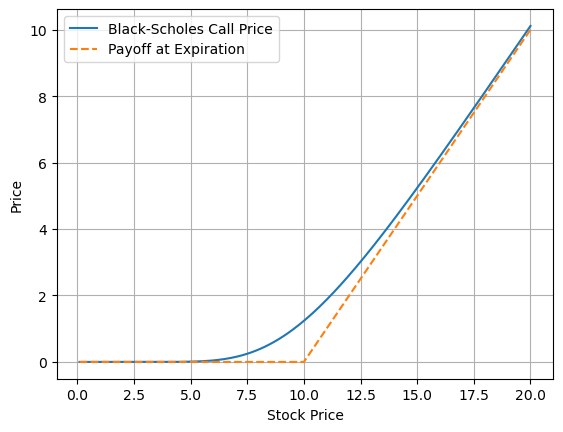

In [29]:
    dx = 0.1  # step to evaluate option for graphing
    maxX = 20.0  # max value of Stock price on graph

    # array of stock prices for which we calculate call price
    X = np.arange(dx, maxX + dx, dx)

    Strike = 10.0
    Rate = 0.01
    Time = 1.0
    Volatility = 0.3

    Y = np.maximum(X - Strike, 0)  # array of Call payoff at expiration
    Z = np.zeros_like(X)

    for i, x_val in enumerate(X):
        Z[i] = BlackScholesStocks("c", x_val, Strike, Rate, Volatility, Time)

    # Plotting the results
    plt.figure()
    plt.plot(X, Z, label="Black-Scholes Call Price")
    plt.plot(X, Y, label="Payoff at Expiration", linestyle="--")
    plt.xlabel("Stock Price")
    plt.ylabel("Price")
    plt.legend()
    plt.grid(True)
    plt.show()

